# 第47章: 混合密度ネットワーク（MDN）— 回帰で「複数の正解」を扱う

## Mixture Density Networks

---

### このノートブックの位置づけ

Notebook 33・34 で混合ガウスモデル（GMM）と EM アルゴリズムを学びました。
あれは「データ全体の分布」を混合分布で表すものでした。

本章では **入力ごとに違う混合分布**を出します。つまり条件付き分布 $p(y \mid x)$ を
混合ガウスでモデル化し、そのパラメータを**ニューラルネットに出力させます**。
これが **混合密度ネットワーク（Mixture Density Network, MDN）** です。

動機は単純です。**1つの入力に対して正解が複数あるとき、ふつうの回帰は壊れます。**
二乗誤差の最適解が「正解たちの平均」になってしまい、平均はどの正解でもないからです。

> この問題は Notebook 172（Diffusion Policy）でも扱いました。
> そこでは**拡散モデル**で解きました。MDN は**同じ問題への別の答え**です。
> 第9節で両者を並べます。

### 学習目標

- [ ] 1入力に複数の正解がある回帰問題（逆問題）を自分で作れる
- [ ] 二乗誤差の最適解が条件付き平均になることを導出し、実測で確認できる
- [ ] ニューラルネットに混合係数・平均・標準偏差を出力させられる
- [ ] 混合負の対数尤度を実装し、**logsumexp が必要な理由**を実測で示せる
- [ ] 混合係数の単体制約と標準偏差の正値制約の扱い方を説明できる
- [ ] 成分数 $K$ の影響と、**学習の不安定性（成分崩壊）**を測定できる
- [ ] 学習した条件分布からサンプルし、予測区間を出せる

### 前提知識

| ノートブック | トピック |
|---|---|
| 33 | 混合ガウスモデル（GMM） |
| 34 | EM アルゴリズム（混合分布の学習） |
| 31 | 最尤推定（負の対数尤度を最小化する） |
| 09 | MLP による回帰 |
| 03 | モデル評価指標 |
| 172 | Diffusion Policy（多峰性への別の答え。本章の後に読み返すと繋がる） |

**難易度**: ★★★☆☆ | **所要時間**: 90-120分

> ⏱ **実行時間**: CPU で約2分です。

## 目次

1. [環境セットアップ](#setup)
2. [多峰性のある回帰問題を作る](#data)
3. [二乗誤差の最適解は条件付き平均](#mean)
4. [MDN の定式化](#mdn)
5. [混合負の対数尤度と logsumexp](#logsumexp)
6. [学習と条件分布の可視化](#train)
7. [成分数 K の影響と学習の不安定性](#k)
8. [サンプリングと予測区間](#sampling)
9. [多峰性への3つの答え](#three)
10. [まとめとチートシート](#summary)
11. [自己評価クイズ](#quiz)

---

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)
print("numpy:", np.__version__)

torch: 2.9.1
numpy: 2.2.6


---

<a id="data"></a>
## 2. 多峰性のある回帰問題を作る

### 逆問題は自然に多峰になる

多峰性のある回帰問題を作る最も自然な方法は、**単調でない関数を逆向きに解く**ことです。

まず $y$ を決めて、

$$x = 7\sin(0.75\,y) + 0.5\,y + \varepsilon$$

で $x$ を作ります。この向き（$y \to x$）は1対1です。
ところが**逆向き（$x \to y$）は1対多**になります。$\sin$ があるので同じ $x$ を与える
$y$ が複数あるからです。

> **Notebook 01（データシミュレーション）の発想と同じ**です。
> 「どういうデータなら、調べたい現象が現れるか」を設計してから作ります。

> **172 で踏んだ落とし穴**: あのときは「場面ごとに正解を振り分ける」データを作って
> しまい、同じ状態に食い違う正解が存在しないため多峰になりませんでした（BC が 0.98 で
> 壊れなかった）。多峰性は **「同じ入力に複数の正解」** でなければ作れません。
> 逆問題はその条件を構造的に満たします。

In [2]:
# ============================================================
# データ生成と、真の解の個数を数える
# ============================================================

AMP, SLOPE, FREQ = 7.0, 0.5, 0.75


def forward_map(y):
    '''y -> x の写像。こちらは1対1。'''
    return AMP * np.sin(FREQ * y) + SLOPE * y


def make_data(n: int, noise: float = 0.5, seed: int = 0):
    '''y を一様にサンプルし、x を作る。学習は x -> y の向きに行う（＝逆問題）。'''
    rng = np.random.default_rng(seed)
    y = rng.uniform(-10.5, 10.5, n)
    x = forward_map(y) + rng.normal(0, noise, n)
    return x.astype(np.float32)[:, None], y.astype(np.float32)[:, None]


def true_solutions(x0: float, tol: float = 0.3, grid: int = 200001):
    '''x0 を与える y を、符号変化から数値的に全部求める（重複は tol でまとめる）。'''
    y = np.linspace(-10.5, 10.5, grid)
    sign = np.sign(forward_map(y) - x0)
    crossings = y[np.where(np.diff(sign) != 0)[0]]
    merged = []
    for c in crossings:
        if not merged or abs(c - merged[-1]) > tol:
            merged.append(c)
    return np.array(merged)


X_train, Y_train = make_data(3000, seed=0)
X_test, Y_test = make_data(1500, seed=1)
print(f"train {X_train.shape}  test {X_test.shape}")
print(f"x range [{X_train.min():.1f}, {X_train.max():.1f}]   y range [-10.5, 10.5]")
print()
print("x を固定したときの真の解の個数:")
for x0 in [-6, -3, 0, 3, 6]:
    sols = true_solutions(x0)
    print(f"  x = {x0:+d}: {len(sols)} 個   y = {np.round(sols, 2)}")

train (3000, 1)  test (1500, 1)
x range [-13.3, 13.1]   y range [-10.5, 10.5]

x を固定したときの真の解の個数:
  x = -6: 3 個   y = [-8.7  -3.29 -1.18]
  x = -3: 5 個   y = [-8.17 -4.   -0.53  5.47  6.83]
  x = +0: 5 個   y = [-7.61 -4.64 -0.    4.64  7.61]
  x = +3: 5 個   y = [-6.83 -5.47  0.53  4.    8.17]
  x = +6: 3 個   y = [1.18 3.29 8.7 ]


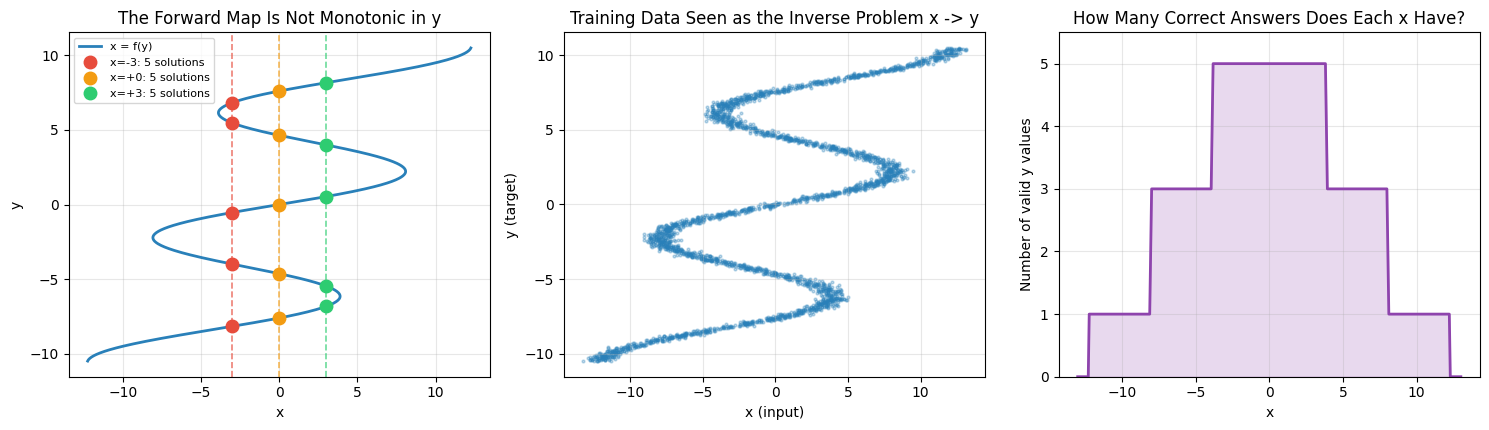

x の範囲のうち、正解が2個以上ある割合: 62%
-> 大部分の入力に対して正解が複数ある。これは例外的な状況ではなく、
   逆問題（観測から原因を推定する問題）では普通に起きる。


In [3]:
# ============================================================
# 図1: 逆問題が多峰になる仕組み
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

# --- 左: 順方向の写像と、x を固定した水平線 ---
ax = axes[0]
y_grid = np.linspace(-10.5, 10.5, 1000)
ax.plot(forward_map(y_grid), y_grid, color="#2980B9", lw=2, label="x = f(y)")
for x0, color in [(-3, "#E74C3C"), (0, "#F39C12"), (3, "#2ECC71")]:
    sols = true_solutions(x0)
    ax.axvline(x0, color=color, ls="--", lw=1.2, alpha=0.7)
    ax.plot([x0] * len(sols), sols, "o", color=color, ms=9,
            label=f"x={x0:+d}: {len(sols)} solutions")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("The Forward Map Is Not Monotonic in y")
ax.legend(fontsize=8)

# --- 中: 学習データ（x -> y の向きで見る） ---
ax = axes[1]
ax.scatter(X_train, Y_train, s=4, alpha=0.3, color="#2980B9")
ax.set_xlabel("x (input)"); ax.set_ylabel("y (target)")
ax.set_title("Training Data Seen as the Inverse Problem x -> y")

# --- 右: x ごとの解の個数 ---
ax = axes[2]
xs = np.linspace(-13, 13, 400)
counts = [len(true_solutions(float(v))) for v in xs]
ax.plot(xs, counts, color="#8E44AD", lw=2)
ax.fill_between(xs, 0, counts, color="#8E44AD", alpha=0.2)
ax.set_xlabel("x"); ax.set_ylabel("Number of valid y values")
ax.set_ylim(0, max(counts) + 0.5)
ax.set_title("How Many Correct Answers Does Each x Have?")

plt.tight_layout()
plt.show()

multi = np.mean([c > 1 for c in counts])
print(f"x の範囲のうち、正解が2個以上ある割合: {multi:.0%}")
print("-> 大部分の入力に対して正解が複数ある。これは例外的な状況ではなく、")
print("   逆問題（観測から原因を推定する問題）では普通に起きる。")

---

<a id="mean"></a>
## 3. 二乗誤差の最適解は条件付き平均

### 導出

二乗誤差を最小化する予測 $\hat y(x)$ は、**条件付き期待値**です。

$$\arg\min_{\hat y} \ \mathbb{E}\left[(\hat y - y)^2 \mid x\right] = \mathbb{E}[y \mid x]$$

導出は1行です。$\frac{\partial}{\partial \hat y}\mathbb{E}[(\hat y - y)^2 \mid x]
= 2(\hat y - \mathbb{E}[y\mid x]) = 0$。

**これは損失関数の性質なので、ネットワークを大きくしても解決しません。**
$p(y\mid x)$ が多峰なら、その平均はどの峰でもない値になります。

Notebook 172 で同じことを行動チャンクについて確認しました。ここでは1次元で、
**平均がどれだけ正解から離れるか**を数値で見ます。

In [4]:
# ============================================================
# ふつうの MSE 回帰を学習する
# ============================================================

def mlp(n_in: int, n_out: int, hidden: int = 64) -> nn.Sequential:
    return nn.Sequential(
        nn.Linear(n_in, hidden), nn.Tanh(),
        nn.Linear(hidden, hidden), nn.Tanh(),
        nn.Linear(hidden, n_out),
    )


def train_mse(epochs: int = 4000, lr: float = 5e-3, seed: int = SEED):
    torch.manual_seed(seed)
    net = mlp(1, 1)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    X, Y = torch.as_tensor(X_train), torch.as_tensor(Y_train)
    history = []
    for _ in range(epochs):
        loss = F.mse_loss(net(X), Y)
        opt.zero_grad(); loss.backward(); opt.step()
        history.append(float(loss.detach()))
    return net, np.array(history)


t0 = time.time()
mse_net, mse_history = train_mse()
var_y = float(np.var(Y_train))
r2 = 1 - mse_history[-1] / var_y
print(f"MSE regression trained in {time.time() - t0:.1f}s")
print(f"  final train MSE : {mse_history[-1]:.2f}")
print(f"  variance of y   : {var_y:.2f}")
print(f"  R^2             : {r2:.3f}   <- 半分しか説明できていない")
print()
print("x ごとに、予測が最も近い正解からどれだけ離れているか:")
for x0 in [-6, -3, 0, 3, 6]:
    with torch.no_grad():
        pred = float(mse_net(torch.as_tensor([[float(x0)]]))[0, 0])
    sols = true_solutions(x0)
    gap = float(np.abs(sols - pred).min())
    print(f"  x = {x0:+d}: 予測 {pred:+6.2f}   正解 {np.round(sols, 2)}"
          f"   最近解まで {gap:.2f}")

MSE regression trained in 4.1s
  final train MSE : 18.39
  variance of y   : 36.88
  R^2             : 0.501   <- 半分しか説明できていない

x ごとに、予測が最も近い正解からどれだけ離れているか:
  x = -6: 予測  -4.13   正解 [-8.7  -3.29 -1.18]   最近解まで 0.83
  x = -3: 予測  +2.39   正解 [-8.17 -4.   -0.53  5.47  6.83]   最近解まで 2.93
  x = +0: 予測  -0.73   正解 [-7.61 -4.64 -0.    4.64  7.61]   最近解まで 0.73
  x = +3: 予測  -1.79   正解 [-6.83 -5.47  0.53  4.    8.17]   最近解まで 2.33
  x = +6: 予測  +3.82   正解 [1.18 3.29 8.7 ]   最近解まで 0.52


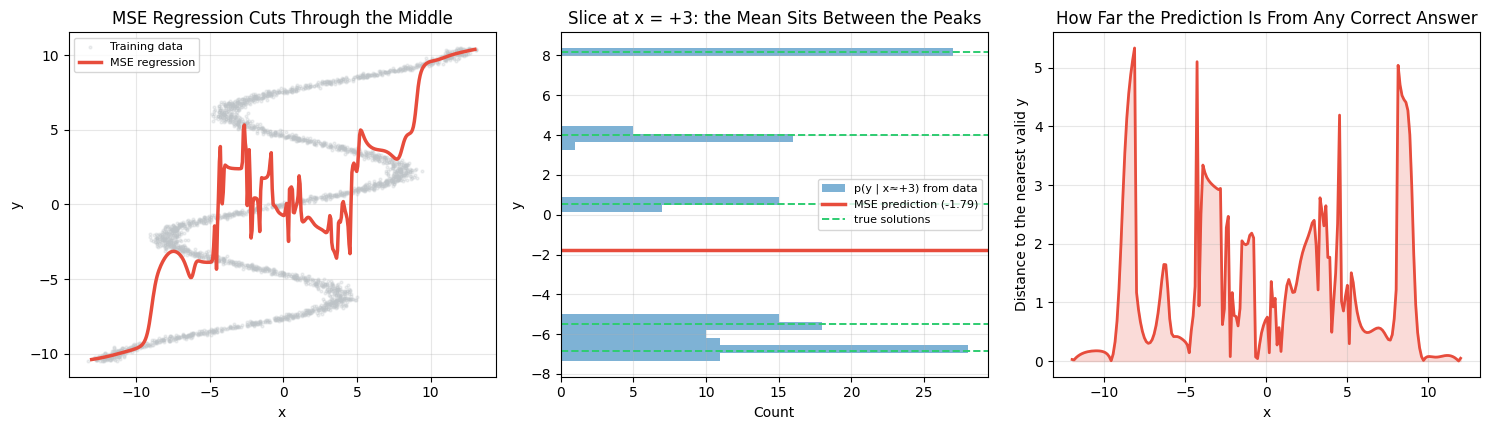

最近解までの距離: 平均 1.22 / 最大 5.34
y の範囲が [-10.5, 10.5] であることを踏まえると、これは小さくない。


In [5]:
# ============================================================
# 図2: 平均はどの正解でもない
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
ax.scatter(X_train, Y_train, s=4, alpha=0.25, color="#BDC3C7", label="Training data")
xs = torch.as_tensor(np.linspace(-13, 13, 400, dtype=np.float32)[:, None])
with torch.no_grad():
    preds = mse_net(xs).numpy().ravel()
ax.plot(xs.numpy().ravel(), preds, color="#E74C3C", lw=2.5, label="MSE regression")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("MSE Regression Cuts Through the Middle")
ax.legend(fontsize=8)

# 中: 代表的な x での断面
ax = axes[1]
x0 = 3.0
band = np.abs(X_train.ravel() - x0) < 0.4
ax.hist(Y_train.ravel()[band], bins=40, orientation="horizontal",
        color="#2980B9", alpha=0.6, label=f"p(y | x≈{x0:+.0f}) from data")
with torch.no_grad():
    pred = float(mse_net(torch.as_tensor([[x0]]))[0, 0])
ax.axhline(pred, color="#E74C3C", lw=2.5, label=f"MSE prediction ({pred:+.2f})")
for s in true_solutions(x0):
    ax.axhline(s, color="#2ECC71", ls="--", lw=1.4)
ax.plot([], [], color="#2ECC71", ls="--", lw=1.4, label="true solutions")
ax.set_xlabel("Count"); ax.set_ylabel("y")
ax.set_title(f"Slice at x = {x0:+.0f}: the Mean Sits Between the Peaks")
ax.legend(fontsize=8)

# 右: 最近解までの距離を x 全体で
ax = axes[2]
xs_eval = np.linspace(-12, 12, 200)
gaps = []
for v in xs_eval:
    with torch.no_grad():
        p = float(mse_net(torch.as_tensor([[float(v)]]))[0, 0])
    sols = true_solutions(float(v))
    gaps.append(float(np.abs(sols - p).min()))
ax.plot(xs_eval, gaps, color="#E74C3C", lw=2)
ax.fill_between(xs_eval, 0, gaps, color="#E74C3C", alpha=0.2)
ax.set_xlabel("x"); ax.set_ylabel("Distance to the nearest valid y")
ax.set_title("How Far the Prediction Is From Any Correct Answer")

plt.tight_layout()
plt.show()

print(f"最近解までの距離: 平均 {np.mean(gaps):.2f} / 最大 {np.max(gaps):.2f}")
print("y の範囲が [-10.5, 10.5] であることを踏まえると、これは小さくない。")

---

<a id="mdn"></a>
## 4. MDN の定式化

### 条件付き分布を混合ガウスで表す

$$p(y \mid x) = \sum_{k=1}^{K} \pi_k(x)\, \mathcal{N}\!\left(y \,\middle|\, \mu_k(x), \sigma_k(x)^2\right)$$

**$\pi$, $\mu$, $\sigma$ がすべて $x$ の関数**であることが要点です。
これをニューラルネットに出力させます。

Notebook 33 の GMM との違いは1点だけです。

| | GMM（33, 34） | MDN（本章） |
|---|---|---|
| 混合パラメータ | データ全体で1組 | **入力ごとに変わる** |
| 学習 | EM アルゴリズム | **勾配降下（NLL を最小化）** |
| 表すもの | $p(y)$ | $p(y \mid x)$ |

### 出力の制約をどう満たすか

ネットワークの生の出力 $(\,a_\pi, a_\mu, a_\sigma\,)$ をそのまま使うことはできません。

| パラメータ | 制約 | 実装 |
|---|---|---|
| $\pi_k$ | $\pi_k \ge 0$, $\sum_k \pi_k = 1$（単体） | `log_softmax`（対数のまま持つ） |
| $\mu_k$ | 制約なし | そのまま |
| $\sigma_k$ | $\sigma_k > 0$ | `exp`（$\log\sigma$ を出力させる） |

**$\pi$ を対数のまま持つのが実装の勘所**です。後で `logsumexp` と組み合わせるときに、
`log_softmax` の出力をそのまま足せるからです。

$\log\sigma$ をクリップしておくのも実務的に重要です。制約がないと $\sigma \to 0$ に
潰れて尤度が発散します（1点に全確率を置くと密度が無限大になる）。

In [6]:
# ============================================================
# MDN の実装
# ============================================================

class MixtureDensityNetwork(nn.Module):
    '''x -> (log pi, mu, log sigma) を出す。混合ガウスで p(y|x) を表す。'''

    def __init__(self, n_components: int = 5, hidden: int = 64,
                 log_sigma_range=(-7.0, 4.0)):
        super().__init__()
        self.K = n_components
        self.log_sigma_min, self.log_sigma_max = log_sigma_range
        # 1本の胴体から 3K 個の値を出し、3つに割る
        self.body = mlp(1, 3 * n_components, hidden)

    def forward(self, x):
        raw_pi, mu, raw_log_sigma = self.body(x).chunk(3, dim=-1)
        log_pi = F.log_softmax(raw_pi, dim=-1)          # 単体制約（対数のまま持つ）
        log_sigma = raw_log_sigma.clamp(self.log_sigma_min, self.log_sigma_max)
        return log_pi, mu, log_sigma

    def log_prob(self, x, y):
        '''log p(y|x) を返す。各成分の対数密度を作って logsumexp でまとめる。'''
        log_pi, mu, log_sigma = self(x)
        # 正規分布の対数密度: -0.5*log(2pi) - log(sigma) - 0.5*((y-mu)/sigma)^2
        log_comp = (-0.5 * np.log(2 * np.pi) - log_sigma
                    - 0.5 * ((y - mu) / log_sigma.exp()) ** 2)
        return torch.logsumexp(log_pi + log_comp, dim=-1)

    def nll(self, x, y):
        '''負の対数尤度（これが損失）。'''
        return -self.log_prob(x, y).mean()

    @torch.no_grad()
    def sample(self, x, n_samples: int = 1):
        '''混合分布からサンプルする: 成分を選んでから、その正規分布から引く。'''
        log_pi, mu, log_sigma = self(x)
        out = []
        for _ in range(n_samples):
            k = torch.distributions.Categorical(logits=log_pi).sample()
            m = mu.gather(1, k[:, None])
            s = log_sigma.exp().gather(1, k[:, None])
            out.append(m + s * torch.randn_like(m))
        return torch.cat(out, dim=-1)

    @torch.no_grad()
    def density_on_grid(self, x, y_grid):
        '''可視化用: 各 x について y_grid 上の密度を返す。'''
        log_pi, mu, log_sigma = self(x)
        y = torch.as_tensor(y_grid, dtype=torch.float32)[None, :, None]
        log_comp = (-0.5 * np.log(2 * np.pi) - log_sigma[:, None, :]
                    - 0.5 * ((y - mu[:, None, :]) / log_sigma.exp()[:, None, :]) ** 2)
        return torch.logsumexp(log_pi[:, None, :] + log_comp, dim=-1).exp().numpy()


demo = MixtureDensityNetwork(n_components=5)
print("parameters:", sum(p.numel() for p in demo.parameters()))
lp, mu, ls = demo(torch.as_tensor([[0.0]]))
print(f"出力の形: log_pi {tuple(lp.shape)}  mu {tuple(mu.shape)}  log_sigma {tuple(ls.shape)}")
print(f"pi の和: {float(lp.exp().sum().detach()):.6f}   <- softmax なので必ず 1")
print(f"sigma の範囲: [{float(ls.exp().min().detach()):.3f}, "
      f"{float(ls.exp().max().detach()):.3f}]   <- exp なので必ず正")

parameters: 5263
出力の形: log_pi (1, 5)  mu (1, 5)  log_sigma (1, 5)
pi の和: 1.000000   <- softmax なので必ず 1
sigma の範囲: [0.924, 1.128]   <- exp なので必ず正


---

<a id="logsumexp"></a>
## 5. 混合負の対数尤度と logsumexp

損失は負の対数尤度です。

$$\mathcal{L} = -\frac{1}{N}\sum_{n} \log \sum_{k=1}^{K} \pi_k(x_n)\,
\mathcal{N}\!\left(y_n \mid \mu_k(x_n), \sigma_k(x_n)^2\right)$$

**素朴に実装すると壊れます。** $\log \sum_k \exp(\cdot)$ の中身が大きな負の数になると、
`exp` が 0 に落ちて `log(0) = -inf` になります。

$y$ が $\mu$ から大きく離れていると $-0.5((y-\mu)/\sigma)^2$ は巨大な負数になるので、
**これは例外ではなく学習の初期に必ず起きます**。

`logsumexp` は最大値を括り出して計算します。

$$\log\sum_k e^{a_k} = a^* + \log\sum_k e^{a_k - a^*}, \quad a^* = \max_k a_k$$

実際に壊れることを確認します。

In [7]:
# ============================================================
# 素朴な実装が壊れることを確認する
# ============================================================

log_pi_demo = torch.log(torch.as_tensor([[0.5, 0.5]]))
mu_demo = torch.as_tensor([[0.0, 0.0]])
sigma_demo = torch.as_tensor([[1.0, 1.0]])

print(f"{'状況':34s} {'素朴な log(sum(exp))':>22s} {'logsumexp':>14s}")
print("-" * 74)
for y_val, label in [(1.0, "ふつう（y が mu の近く）"),
                     (10.0, "やや外れ（y - mu = 10）"),
                     (40.0, "学習初期に普通に起きる（= 40）")]:
    y = torch.as_tensor([[y_val]])
    log_comp = (-0.5 * np.log(2 * np.pi) - sigma_demo.log()
                - 0.5 * ((y - mu_demo) / sigma_demo) ** 2)
    naive = torch.log((log_pi_demo + log_comp).exp().sum(dim=-1))
    stable = torch.logsumexp(log_pi_demo + log_comp, dim=-1)
    print(f"{label:34s} {float(naive):>22.3f} {float(stable):>14.3f}")

print()
print("y - mu が 40 程度になると、素朴な実装は -inf を返す。")
print("損失が -inf になれば勾配は nan になり、学習はその時点で死ぬ。")
print("y の範囲が [-10.5, 10.5] でランダム初期化なら、この状況は初期に必ず起きる。")

状況                                      素朴な log(sum(exp))      logsumexp
--------------------------------------------------------------------------
ふつう（y が mu の近く）                                    -1.419         -1.419
やや外れ（y - mu = 10）                                 -50.919        -50.919
学習初期に普通に起きる（= 40）                                    -inf       -800.919

y - mu が 40 程度になると、素朴な実装は -inf を返す。
損失が -inf になれば勾配は nan になり、学習はその時点で死ぬ。
y の範囲が [-10.5, 10.5] でランダム初期化なら、この状況は初期に必ず起きる。


---

<a id="train"></a>
## 6. 学習と条件分布の可視化

MDN を学習し、**学習した $p(y\mid x)$ を真の分岐と重ねて**見ます。
回帰のときは「1本の線」でしたが、ここでは「分布の帯」が出ます。

In [8]:
# ============================================================
# MDN の学習
# ============================================================

def train_mdn(n_components: int = 5, epochs: int = 4000, lr: float = 5e-3,
              seed: int = SEED, clip: float = 5.0):
    torch.manual_seed(seed)
    net = MixtureDensityNetwork(n_components)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    X, Y = torch.as_tensor(X_train), torch.as_tensor(Y_train)
    history = []
    for _ in range(epochs):
        loss = net.nll(X, Y)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), clip)
        opt.step()
        history.append(float(loss.detach()))
    with torch.no_grad():
        test_nll = float(net.nll(torch.as_tensor(X_test), torch.as_tensor(Y_test)))
    return net, np.array(history), test_nll


t0 = time.time()
mdn, mdn_history, mdn_test_nll = train_mdn(n_components=10)
print(f"MDN (K=10) trained in {time.time() - t0:.1f}s")
print(f"  final train NLL : {mdn_history[-1]:+.3f}")
print(f"  test NLL        : {mdn_test_nll:+.3f}")

MDN (K=10) trained in 6.8s
  final train NLL : +0.792
  test NLL        : +1.099


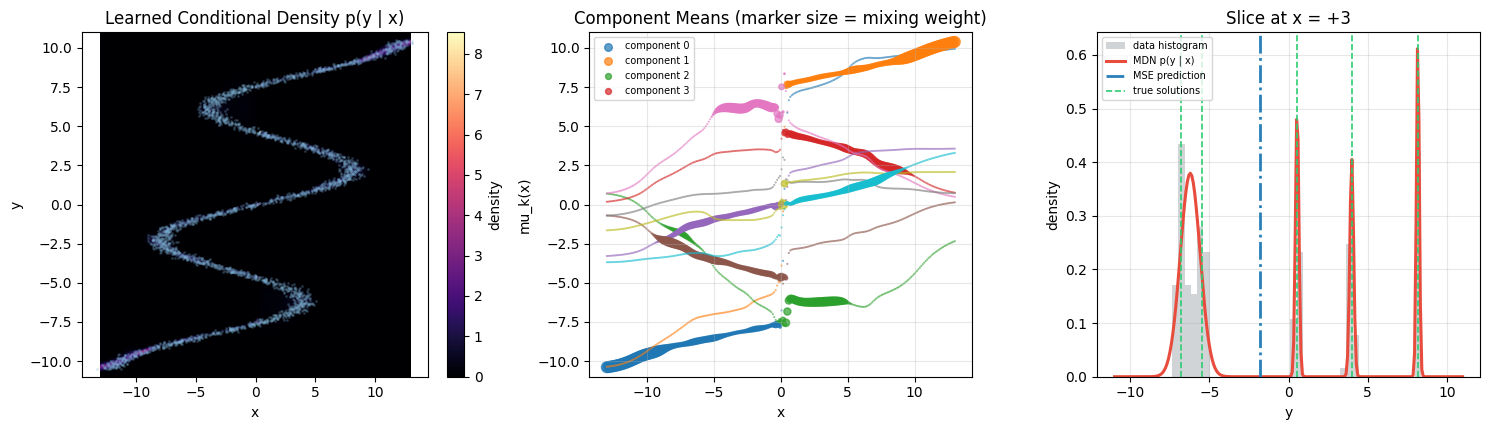

MDN は1本の線ではなく「分布の帯」を出す。
真の分岐（緑の破線）のうち、どれだけを拾えているかは第7節で定量化する。


In [9]:
# ============================================================
# 図3: 学習した条件分布 p(y|x)
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

x_grid = np.linspace(-13, 13, 240, dtype=np.float32)
y_grid = np.linspace(-11, 11, 240, dtype=np.float32)
density = mdn.density_on_grid(torch.as_tensor(x_grid[:, None]), y_grid)

ax = axes[0]
im = ax.imshow(density.T, origin="lower", aspect="auto", cmap="magma",
               extent=[x_grid[0], x_grid[-1], y_grid[0], y_grid[-1]])
ax.scatter(X_train, Y_train, s=1.5, alpha=0.18, color="#7FB3D5")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Learned Conditional Density p(y | x)")
ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.046, label="density")

# 中: 混合の成分（mu を重み付きで描く）
ax = axes[1]
with torch.no_grad():
    log_pi, mu, log_sigma = mdn(torch.as_tensor(x_grid[:, None]))
w = log_pi.exp().numpy(); mu_np = mu.numpy()
for k in range(mdn.K):
    ax.scatter(x_grid, mu_np[:, k], s=np.clip(w[:, k] * 60, 0.2, 60),
               alpha=0.7, label=f"component {k}" if k < 4 else None)
ax.set_xlabel("x"); ax.set_ylabel("mu_k(x)")
ax.set_ylim(-11, 11)
ax.set_title("Component Means (marker size = mixing weight)")
ax.legend(fontsize=7, loc="upper left")

# 右: 断面での比較
ax = axes[2]
x0 = 3.0
dens = mdn.density_on_grid(torch.as_tensor([[x0]]), y_grid)[0]
band = np.abs(X_train.ravel() - x0) < 0.4
ax.hist(Y_train.ravel()[band], bins=40, density=True, color="#BDC3C7",
        alpha=0.7, label="data histogram")
ax.plot(y_grid, dens, color="#E74C3C", lw=2.2, label="MDN p(y | x)")
with torch.no_grad():
    mse_pred = float(mse_net(torch.as_tensor([[x0]]))[0, 0])
ax.axvline(mse_pred, color="#2980B9", lw=2, ls="-.", label="MSE prediction")
for s in true_solutions(x0):
    ax.axvline(s, color="#2ECC71", ls="--", lw=1.2)
ax.plot([], [], color="#2ECC71", ls="--", lw=1.2, label="true solutions")
ax.set_xlabel("y"); ax.set_ylabel("density")
ax.set_title(f"Slice at x = {x0:+.0f}")
ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

print("MDN は1本の線ではなく「分布の帯」を出す。")
print("真の分岐（緑の破線）のうち、どれだけを拾えているかは第7節で定量化する。")

---

<a id="k"></a>
## 7. 成分数 K の影響と学習の不安定性

### K を振る

$K=1$ なら単一ガウス、つまり **「分散も学ぶ回帰」** です。
$K$ を増やすと多峰を表現できるようになります。

同時に、**どれだけ真の分岐を拾えたか**を測ります。
「重み 0.05 を超える成分が、真の解の 0.8 以内にあるか」で数えます。

In [10]:
# ============================================================
# K スイープ: NLL と分岐の回復
# ============================================================

def count_recovered_modes(net, x0: float = 0.0,
                          weight_threshold: float = 0.05, tol: float = 0.8):
    with torch.no_grad():
        log_pi, mu, _ = net(torch.as_tensor([[float(x0)]]))
    w = log_pi.exp().numpy().ravel()
    m = mu.numpy().ravel()
    active = m[w > weight_threshold]
    sols = true_solutions(x0)
    recovered = sum(1 for s in sols
                    if len(active) and np.min(np.abs(active - s)) < tol)
    return len(active), recovered, len(sols)


K_VALUES = [1, 2, 3, 5, 10, 20]
k_rows = []
t0 = time.time()
for K in K_VALUES:
    net, hist, test_nll = train_mdn(n_components=K)
    n_active, recovered, n_sols = count_recovered_modes(net)
    k_rows.append({"K": K, "test_nll": test_nll, "active": n_active,
                   "recovered": recovered, "n_sols": n_sols,
                   "final_train": hist[-1]})
print(f"K sweep finished in {time.time() - t0:.0f}s")
print(f"{'K':>3s} {'test NLL':>10s} {'活性成分':>9s} {'分岐の回復':>12s}")
for r in k_rows:
    print(f"{r['K']:3d} {r['test_nll']:+10.3f} {r['active']:9d} "
          f"{r['recovered']:>6d}/{r['n_sols']:<5d}")

K sweep finished in 42s
  K   test NLL      活性成分        分岐の回復
  1     +2.522         1      1/5    
  2     +1.795         2      1/5    
  3     +2.335         3      2/5    
  5     +1.126         4      3/5    
 10     +1.099         4      4/5    
 20     +0.957         4      4/5    


### 学習の不安定性を測る

上の表で $K=3$ の NLL が他より悪く見えます。ここで **「$K=3$ は悪い」と結論すると
間違い**です。MDN の学習は初期値に強く依存するので、**シードを振って分布を見ないと
何も言えません**。

実際に測ります。

seed study finished in 96s


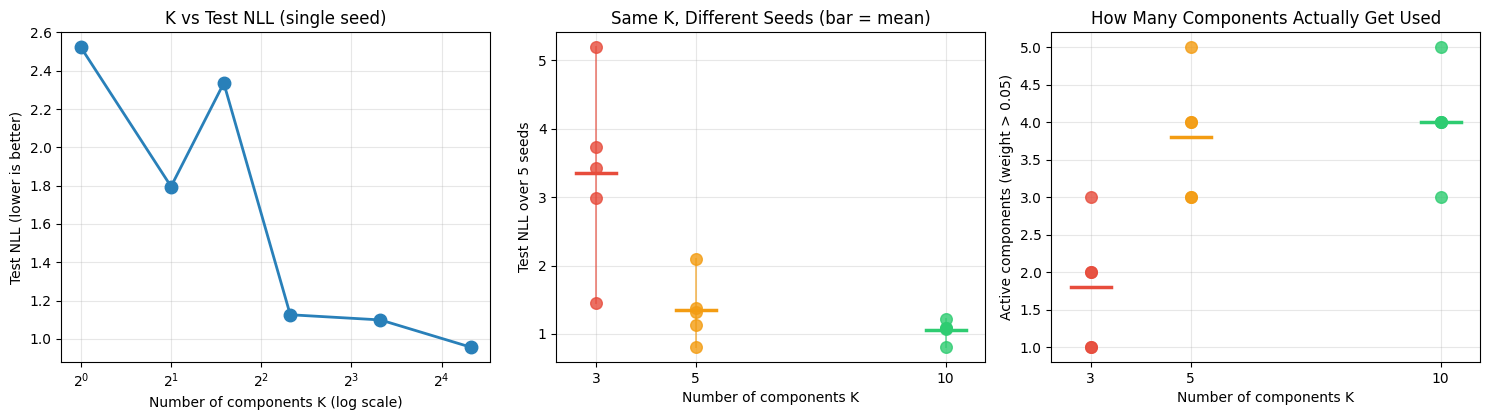

  K   NLL mean      std     best    worst         活性成分
  3     +3.359    1.205   +1.452   +5.189 1-3 (mean 1.8)
  5     +1.347    0.424   +0.807   +2.095 3-5 (mean 3.8)
 10     +1.054    0.133   +0.808   +1.212 3-5 (mean 4.0)


In [11]:
# ============================================================
# 図4: K の影響と、シード依存性
# ============================================================

SEEDS = [0, 1, 2, 3, 4]
seed_rows = {}
t0 = time.time()
for K in [3, 5, 10]:
    vals = []
    for sd in SEEDS:
        net, hist, test_nll = train_mdn(n_components=K, seed=sd)
        n_active, recovered, n_sols = count_recovered_modes(net)
        vals.append({"seed": sd, "nll": test_nll, "active": n_active,
                     "recovered": recovered})
    seed_rows[K] = vals
print(f"seed study finished in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

ax = axes[0]
ax.plot([r["K"] for r in k_rows], [r["test_nll"] for r in k_rows],
        "o-", color="#2980B9", lw=2, ms=9)
ax.set_xscale("log", base=2)
ax.set_xlabel("Number of components K (log scale)")
ax.set_ylabel("Test NLL (lower is better)")
ax.set_title("K vs Test NLL (single seed)")

ax = axes[1]
for K, color in zip([3, 5, 10], ["#E74C3C", "#F39C12", "#2ECC71"]):
    nlls = [v["nll"] for v in seed_rows[K]]
    ax.scatter([K] * len(nlls), nlls, s=70, color=color, alpha=0.8, zorder=3)
    ax.plot([K - 0.4, K + 0.4], [np.mean(nlls)] * 2, color=color, lw=2.5)
    ax.plot([K, K], [min(nlls), max(nlls)], color=color, lw=1.4, alpha=0.6)
ax.set_xticks([3, 5, 10])
ax.set_xlabel("Number of components K")
ax.set_ylabel("Test NLL over 5 seeds")
ax.set_title("Same K, Different Seeds (bar = mean)")

ax = axes[2]
for K, color in zip([3, 5, 10], ["#E74C3C", "#F39C12", "#2ECC71"]):
    act = [v["active"] for v in seed_rows[K]]
    ax.scatter([K] * len(act), act, s=70, color=color, alpha=0.8, zorder=3)
    ax.plot([K - 0.4, K + 0.4], [np.mean(act)] * 2, color=color, lw=2.5)
ax.set_xticks([3, 5, 10])
ax.set_xlabel("Number of components K")
ax.set_ylabel("Active components (weight > 0.05)")
ax.set_title("How Many Components Actually Get Used")

plt.tight_layout()
plt.show()

print(f"{'K':>3s} {'NLL mean':>10s} {'std':>8s} {'best':>8s} {'worst':>8s} {'活性成分':>12s}")
for K in [3, 5, 10]:
    nlls = [v["nll"] for v in seed_rows[K]]
    act = [v["active"] for v in seed_rows[K]]
    print(f"{K:3d} {np.mean(nlls):+10.3f} {np.std(nlls):8.3f} "
          f"{min(nlls):+8.3f} {max(nlls):+8.3f} "
          f"{min(act)}-{max(act)} (mean {np.mean(act):.1f})")

### 読み取れること

- **$K$ を増やすと NLL は概ね下がる**（表現力が上がる）。ただし **単調ではありません**。
  実測では $K=3$ が $K=2$ より悪く出ました。
- **その非単調性の正体はシード依存です**。同じ $K$ でもシードで大きくばらつき、
  $K=3$ では最良と最悪で NLL が3倍以上違いました。
  **単一シードの結果を「$K=3$ の性質」と書いてはいけません。**
- **$K$ を増やすとばらつきも小さくなる**。標準偏差が縮みます。
  成分が多いほど「どれかが当たる」ので、初期値の悪さから回復しやすいと解釈できます。
- **成分崩壊（component collapse）が起きる**。$K$ 個用意しても、重みがほぼ 0 になって
  使われない成分が出ます。$K=3$ では活性成分が 1 個まで潰れるシードがありました。

> **成分崩壊への実務的な対処**（本章では実装していません）:
> 混合係数にエントロピー正則化をかける、$\log\sigma$ の下限を上げる、
> $K$ を大きめに取って余らせる、複数シードで学習して最良を選ぶ。
> **「$K$ を大きめに取る」が一番簡単で効果的**なのが上の実測から読めます。

### 真の分岐をすべて拾えたわけではない

分岐の回復は $K$ を増やしても途中で止まります。
$p(y\mid x)$ の周辺（$|y|$ が大きい分岐）はデータが相対的に薄く、
$\sigma$ が大きい成分に吸収されてしまうためです。
**「混合分布にすれば多峰が全部取れる」わけではない**ことを押さえてください。

---

<a id="sampling"></a>
## 8. サンプリングと予測区間

MDN は分布を出すので、**サンプルを引ける**し**予測区間が出せる**ようになります。
点予測しか出せない回帰との決定的な違いです。

サンプリングは2段階です。

1. 混合係数 $\pi(x)$ に従って成分 $k$ を選ぶ（カテゴリカル分布）
2. その成分の正規分布 $\mathcal{N}(\mu_k, \sigma_k^2)$ から引く

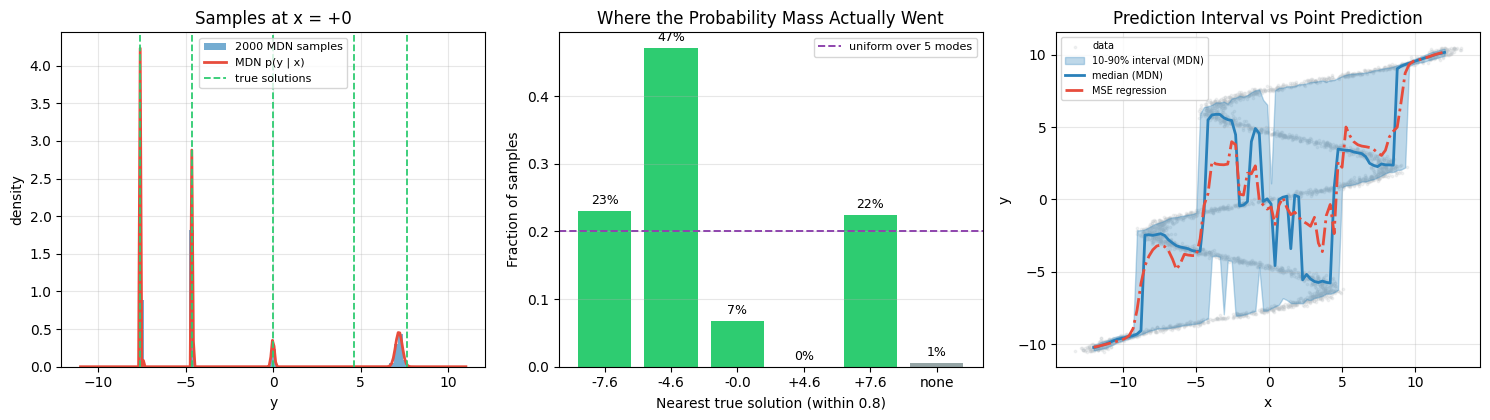

各モードに乗った確率質量:
  y =  -7.61: 23.1%
  y =  -4.64: 47.1%
  y =  -0.00: 6.8%
  y =  +4.64: 0.0%
  y =  +7.61: 22.4%
  どのモードにも入らなかった: 0.5%

一様なら各モード 20.0% のはず。実測は偏っている。
質量がほぼ乗らなかったモード: +4.64  <- 取りこぼし
MDN は多峰を表現できるが、真の条件分布を忠実に再現しているわけではない。


In [12]:
# ============================================================
# 図5: サンプリングと予測区間
# ============================================================

N_SAMPLES = 2000
x0 = 0.0

samples = mdn.sample(torch.as_tensor([[x0]] * N_SAMPLES), n_samples=1).numpy().ravel()
sols = true_solutions(x0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

ax = axes[0]
ax.hist(samples, bins=60, density=True, color="#2980B9", alpha=0.65,
        label=f"{N_SAMPLES} MDN samples")
dens = mdn.density_on_grid(torch.as_tensor([[x0]]), y_grid)[0]
ax.plot(y_grid, dens, color="#E74C3C", lw=2, label="MDN p(y | x)")
for s in sols:
    ax.axvline(s, color="#2ECC71", ls="--", lw=1.3)
ax.plot([], [], color="#2ECC71", ls="--", lw=1.3, label="true solutions")
ax.set_xlabel("y"); ax.set_ylabel("density")
ax.set_title(f"Samples at x = {x0:+.0f}")
ax.legend(fontsize=8)

# 中: 各モードにどれだけ質量が乗ったか
ax = axes[1]
fractions = [float(np.mean(np.abs(samples - s) < 0.8)) for s in sols]
outside = float(np.mean([min(abs(v - s) for s in sols) >= 0.8 for v in samples]))
labels = [f"{s:+.1f}" for s in sols] + ["none"]
vals = fractions + [outside]
bars = ax.bar(labels, vals, color=["#2ECC71"] * len(sols) + ["#95A5A6"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.0%}",
            ha="center", fontsize=9)
ax.axhline(1 / len(sols), color="#8E44AD", ls="--", lw=1.4,
           label=f"uniform over {len(sols)} modes")
ax.set_xlabel("Nearest true solution (within 0.8)")
ax.set_ylabel("Fraction of samples")
ax.set_title("Where the Probability Mass Actually Went")
ax.legend(fontsize=8)
ax.grid(axis="x")

# 右: 予測区間（分位点）
ax = axes[2]
x_line = np.linspace(-12, 12, 90, dtype=np.float32)
q10, q50, q90 = [], [], []
for v in x_line:
    s = mdn.sample(torch.as_tensor([[float(v)]] * 400), n_samples=1).numpy().ravel()
    q10.append(np.quantile(s, 0.10)); q50.append(np.quantile(s, 0.50))
    q90.append(np.quantile(s, 0.90))
ax.scatter(X_train, Y_train, s=3, alpha=0.2, color="#BDC3C7", label="data")
ax.fill_between(x_line, q10, q90, color="#2980B9", alpha=0.3,
                label="10-90% interval (MDN)")
ax.plot(x_line, q50, color="#2980B9", lw=2, label="median (MDN)")
with torch.no_grad():
    ax.plot(x_line, mse_net(torch.as_tensor(x_line[:, None])).numpy().ravel(),
            color="#E74C3C", lw=2, ls="-.", label="MSE regression")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Prediction Interval vs Point Prediction")
ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

print("各モードに乗った確率質量:")
for s, f in zip(sols, fractions):
    print(f"  y = {s:+6.2f}: {f:.1%}")
print(f"  どのモードにも入らなかった: {outside:.1%}")
print()
print(f"一様なら各モード {1/len(sols):.1%} のはず。実測は偏っている。")
zero_modes = [f"{s:+.2f}" for s, f in zip(sols, fractions) if f < 0.01]
if zero_modes:
    print(f"質量がほぼ乗らなかったモード: {', '.join(zero_modes)}  <- 取りこぼし")
print("MDN は多峰を表現できるが、真の条件分布を忠実に再現しているわけではない。")

### 読み取れること — 多峰を「表現できる」と「正しく再現する」は違う

サンプルの質量は**特定のモードに偏りました**。一様に近い分布を期待していたなら、
これは期待外れです。しかも**質量がまったく乗らなかったモードがあります**。

一方で、**どのモードにも属さないサンプルはごく少数**でした。
つまり起きているのは「$\sigma$ が大きい成分がモード間の谷を埋めている」ではなく、
**モードそのものを取りこぼしている**ということです。
第7節で測った分岐の回復が最大 4/5 で止まったことと整合します（＝成分崩壊）。

残る偏りには、**正しい偏りも含まれます**。データ上の密度はモードごとに違い、
$|dx/dy|$ が小さいところ（写像が平らなところ）に $y$ が溜まるので、
真の $p(y\mid x)$ 自体が一様ではありません。
**どこまでが正しい偏りで、どこからが取りこぼしかは本章では切り分けていません。**

押さえるべきは「MDN は多峰を表現する枠組みを持つが、忠実な再現は別問題」という点です。

一方で、**予測区間が出せる**こと自体は MSE 回帰には絶対にできない利点です（右図）。
点予測しか返せないモデルでは「この入力は答えが複数ある」ことすら表現できません。

---

<a id="three"></a>
## 9. 多峰性への3つの答え

本リポジトリには、同じ「1入力に複数の正解」問題への答えが3つあります。

| 手法 | どう表すか | 章 | 長所 | 短所 |
|---|---|---|---|---|
| **混合分布（MDN）** | $K$ 個のガウスの重み付き和 | **本章** | 密度が閉形式で出る。予測区間が出せる。軽い | 成分崩壊・初期値依存。$K$ を決める必要がある |
| **離散トークン化** | 値をビンに区切って分類 | 171 | 多峰を自然に表現。言語モデルに繋げられる | 量子化誤差。**各次元独立だと同時分布を壊す** |
| **拡散モデル** | ノイズから反復的に生成 | 172 | 同時分布を一貫して扱える。高次元に強い | 学習・推論が重い。密度が直接出ない |

### 172 の実測と並べる

Notebook 172 では行動チャンク（16ステップ × 2次元 = 32次元）の多峰性を扱い、
**開ループ実行の成功率**で比較しました。

- 回帰（＝条件付き平均）: **0.08**
- 離散トークン（各ステップ独立の softmax）: **0.36**
- 拡散方針: **0.80**

本章の MDN は 172 では試していません。**1次元なら MDN で足りる**一方、
172 のように**32次元の同時分布**が必要な場面では、
混合分布の成分数が足りなくなります（モードの組み合わせが指数的に増える）。

> **選び方の目安**:
> 出力が低次元（1〜数次元）で密度や予測区間が欲しいなら **MDN**。
> 言語モデルに繋げたいなら **トークン化**。
> 高次元で時間的・空間的に一貫した出力が必要なら **拡散**。

### 147 への接続

本章の MDN を**系列に拡張**すると、$p(z_{t+1} \mid z_t, a_t, h_t)$ を混合ガウスで
予測する **MDN-RNN** になります。これが Ha & Schmidhuber (2018) の World Models の
中核で、Notebook 147 で実装します（146 が「独立章なし」と注記している穴）。

「次の状態は複数あり得る」——交差点に来た車は左折も直進も右折もできる——という
多峰性が、世界モデルでも本質的に必要になります。

---

<a id="summary"></a>
## 10. まとめとチートシート

### この章で学んだこと

- **二乗誤差の最適解は条件付き平均** $\mathbb{E}[y\mid x]$。損失関数の性質なので、
  ネットワークを大きくしても多峰性は扱えない。
- **逆問題は構造的に多峰になる**。単調でない写像を逆に解くと1対多になる。
  多峰データは「同じ入力に複数の正解」でなければ作れない（172 で踏んだ落とし穴）。
- **MDN は $\pi$, $\mu$, $\sigma$ をすべて $x$ の関数として出す**。
  GMM との違いは「入力ごとに変わる」ことと「EM ではなく勾配降下」の2点だけ。
- **制約の実装**: $\pi$ は `log_softmax`（対数のまま持つ）、$\sigma$ は $\log\sigma$ を
  出して `exp`、さらにクリップして $\sigma \to 0$ の発散を防ぐ。
- **`logsumexp` は必須**。素朴な `log(sum(exp(·)))` は学習初期に `-inf` を返し、
  勾配が nan になって学習が死ぬ。実測で確認した。
- **MDN の学習は初期値に強く依存する**。同じ $K$ でもシードで NLL が数倍違う。
  **単一シードの結果を手法の性質として書いてはいけない。**
- **成分崩壊が起きる**。$K$ を大きめに取るのが最も簡単な対処。
- **多峰を「表現できる」と「正しく再現する」は別**。サンプルの質量は偏り、
  質量がまったく乗らないモードもあった（谷を埋めたのではなく取りこぼした）。

### チートシート

```python
# 出力の制約（ここが実装の勘所）
raw_pi, mu, raw_log_sigma = net(x).chunk(3, dim=-1)
log_pi    = F.log_softmax(raw_pi, dim=-1)              # 対数のまま持つ
log_sigma = raw_log_sigma.clamp(-7.0, 4.0)             # sigma -> 0 の発散を防ぐ

# 混合の対数尤度（logsumexp で安定化）
log_comp = (-0.5 * np.log(2 * np.pi) - log_sigma
            - 0.5 * ((y - mu) / log_sigma.exp()) ** 2)
log_prob = torch.logsumexp(log_pi + log_comp, dim=-1)  # log(sum(exp(...))) は使わない
loss = -log_prob.mean()

# サンプリング（2段階）
k = torch.distributions.Categorical(logits=log_pi).sample()   # 成分を選ぶ
y = mu.gather(1, k[:, None]) + log_sigma.exp().gather(1, k[:, None]) * torch.randn(...)
```

### よくある間違い

| 間違い | 何が起きるか | 対処 |
|---|---|---|
| `log(sum(exp(...)))` と素朴に書く | 学習初期に `-inf` → 勾配が nan | `torch.logsumexp` を使う |
| $\sigma$ を直接出力させる | 負になる／0 に潰れて尤度が発散 | $\log\sigma$ を出して `exp`、さらにクリップ |
| $\pi$ を確率のまま持つ | 対数尤度で `log` を取り直して精度を落とす | `log_softmax` で対数のまま持つ |
| 単一シードで $K$ を比較する | 初期値の運を手法の性質と誤認する | **複数シードで分布を見る**（本章の第7節） |
| 成分数を最小限にする | 成分崩壊して多峰を拾えない | $K$ を大きめに取って余らせる |
| MSE で多峰性を扱おうとする | 平均に潰れる（損失の性質なので回避不能） | 損失を変える（NLL）か出力を分布にする |
| 高次元の同時分布に MDN を使う | モードの組み合わせが指数的に増えて破綻 | 拡散モデル（172）か自己回帰を使う |

### 次に読むもの

- **172（Diffusion Policy）** を読み返すと、同じ問題への別解として繋がります
- **147（World Models 原典）** で本章の MDN が MDN-RNN として系列に拡張されます
- **46（PixelCNN）** は「分布を出す」別の方法（離散値の自己回帰）です
- **195（スコアマッチングと拡散モデルの統合）** では、密度を扱う系統の全体像が出ます

---

<a id="quiz"></a>
## 11. 自己評価クイズ

### Q1: なぜネットワークを大きくしても解決しないのか

**問題**: 多峰性のある回帰で、MSE 損失のまま隠れ層を10倍にしたら解決しますか。
理由を数式で説明してください。

<details>
<summary>答えを見る</summary>

解決しません。

$\arg\min_{\hat y}\mathbb{E}[(\hat y - y)^2 \mid x] = \mathbb{E}[y \mid x]$ は
**損失関数の性質**で、モデルの表現力とは無関係です。
むしろ表現力が上がるほど、条件付き平均を**より正確に**再現するようになります。

$\frac{\partial}{\partial \hat y}\mathbb{E}[(\hat y - y)^2\mid x]
= 2(\hat y - \mathbb{E}[y\mid x]) = 0 \Rightarrow \hat y = \mathbb{E}[y\mid x]$。

解決には **損失を変える**（NLL にする）か **出力を分布にする**（MDN・拡散・トークン化）
必要があります。
</details>

---

### Q2: logsumexp が必要な場面

**問題**: 混合負の対数尤度で `log(sum(exp(...)))` と素朴に書くと、
どういう状況で壊れますか。その状況が「例外的でない」理由も述べてください。

<details>
<summary>答えを見る</summary>

各成分の対数密度に $-\frac{1}{2}\left(\frac{y-\mu}{\sigma}\right)^2$ が入るので、
$y$ が $\mu$ から離れていると巨大な負数になります。
`exp` がアンダーフローして 0 になり、`log(0) = -inf`、勾配は nan になります。

**例外的でない理由**: 学習の初期は $\mu$ がランダムなので、$y$ と $\mu$ が
大きく離れているのが普通です。本章の実測では $y-\mu = 40$ で既に `-inf` でした
（$y$ の範囲が $[-10.5, 10.5]$ なので、ランダム初期化なら初期に必ず起きます）。

`logsumexp` は $\log\sum_k e^{a_k} = a^* + \log\sum_k e^{a_k - a^*}$ と
最大値を括り出すので、指数の引数が必ず $\le 0$ になり安全です。
</details>

---

### Q3: 単一シードで比較してはいけない理由

**問題**: 本章の $K$ スイープで $K=3$ の NLL が他より悪く出ました。
ここから「$K=3$ は不適切」と結論してよいですか。

<details>
<summary>答えを見る</summary>

よくありません。**シードを振ると $K=3$ の NLL は大きくばらつきました**
（最良と最悪で数倍の差）。単一シードの値は初期値の運を含んでいます。

言えるのは「$K$ が小さいと成分崩壊が起きやすく、結果のばらつきが大きい」という
ことです。これは「$K=3$ が悪い」とは別の主張で、対処（$K$ を大きめに取る、
複数シードで最良を選ぶ）も変わります。

一般に、**初期値に依存する手法を比較するときは必ず複数シードで分布を見る**
必要があります。平均だけでなくばらつきも報告します。
</details>

---

### Q4: MDN と拡散モデルの使い分け

**問題**: Notebook 172 では行動チャンク（32次元）の多峰性を拡散モデルで扱いました。
ここに MDN を使うとどう苦しいですか。逆に MDN が有利な場面は何ですか。

<details>
<summary>答えを見る</summary>

**MDN が苦しい理由**: 32次元の同時分布で、各次元が独立に複数のモードを持つと、
モードの**組み合わせ**が指数的に増えます。16ステップのそれぞれで左右2通りなら
$2^{16}$ 通りで、これを $K$ 個のガウスで覆うのは非現実的です。
対角共分散では次元間の相関も表せません。

**MDN が有利な場面**: 出力が低次元（1〜数次元）で、

- **密度が閉形式で欲しい**（異常検知、尤度比検定）
- **予測区間が欲しい**（分位点を計算できる）
- **軽さが要る**（1回の前向き計算で分布が出る。拡散は反復が必要）

本章の1次元逆問題はまさにこの条件で、拡散モデルを持ち出す必要はありません。
</details>

---

### Q5: 多峰を表現できることと再現することの違い

**問題**: 本章の MDN はサンプルの質量が特定のモードに偏りました。
「MDN は多峰性を扱える」という主張とこの観察は矛盾しますか。

<details>
<summary>答えを見る</summary>

矛盾しません。**「表現できる枠組みを持つ」ことと「正しく再現する」ことは別**です。

混合分布は原理的に多峰を表現できます（MSE 回帰は原理的に不可能）。
しかし実際に学習された分布が真の $p(y\mid x)$ と一致するかは、
データ量・成分数・初期値・最適化の全部に依存します。

本章で観察された偏りの原因候補は、①データ上の密度がモードごとに違う（偏りが
正しい場合もある）②成分崩壊で拾えていないモードがある ③$\sigma$ が大きい成分が
モード間を埋めている、です。**本章ではこの切り分けをしていません**。

教材として重要なのは、「手法が原理的に可能にすること」と「実測で得られたこと」を
分けて書くことです。
</details>

In [13]:
# ============================================================
# 最終サマリ
# ============================================================

best_k = min(k_rows, key=lambda r: r["test_nll"])
print("=" * 70)
print("Notebook 47 完了: 混合密度ネットワーク（MDN）")
print("=" * 70)
print(f'''
【問題設定】 x = 7 sin(0.75 y) + 0.5 y + ε を x -> y と逆に解く
            大部分の x に対して正解が複数ある（最大 {max(len(true_solutions(float(v))) for v in np.linspace(-12,12,100))} 個）

【MSE 回帰（条件付き平均）】

  訓練 MSE {mse_history[-1]:.2f} / y の分散 {var_y:.2f} -> R^2 {r2:.3f}
  予測は最も近い正解から平均 {np.mean(gaps):.2f} 離れる（最大 {np.max(gaps):.2f}）
  -> 損失の性質なので、モデルを大きくしても直らない

【MDN】
''' + "\n".join(
    f"  K={r['K']:2d}: test NLL {r['test_nll']:+.3f}  活性成分 {r['active']:2d}"
    f"  分岐の回復 {r['recovered']}/{r['n_sols']}" for r in k_rows) + f'''

  最良は K={best_k['K']}（test NLL {best_k['test_nll']:+.3f}）

【学習の不安定性（5シード）】
''' + "\n".join(
    f"  K={K:2d}: NLL 平均 {np.mean([v['nll'] for v in seed_rows[K]]):+.3f} "
    f"標準偏差 {np.std([v['nll'] for v in seed_rows[K]]):.3f} "
    f"（最良 {min(v['nll'] for v in seed_rows[K]):+.3f} / 最悪 {max(v['nll'] for v in seed_rows[K]):+.3f}）"
    for K in [3, 5, 10]) + f'''

  -> 単一シードの結果を手法の性質として書いてはいけない。
     K を大きくするとばらつきも小さくなる。

【サンプリング】

  各モードに乗った質量は偏った（一様なら各 {1/len(true_solutions(0.0)):.0%} のはず）
  どのモードにも入らなかったサンプル: {outside:.1%}
  -> 多峰を「表現できる」と「正しく再現する」は別

【次に読むもの】

  172 Diffusion Policy  — 同じ問題への別解（32次元の同時分布）
  147 World Models 原典 — 本章の MDN が MDN-RNN として系列に拡張される
''')
print("=" * 70)

Notebook 47 完了: 混合密度ネットワーク（MDN）

【問題設定】 x = 7 sin(0.75 y) + 0.5 y + ε を x -> y と逆に解く
            大部分の x に対して正解が複数ある（最大 5 個）

【MSE 回帰（条件付き平均）】

  訓練 MSE 18.39 / y の分散 36.88 -> R^2 0.501
  予測は最も近い正解から平均 1.22 離れる（最大 5.34）
  -> 損失の性質なので、モデルを大きくしても直らない

【MDN】
  K= 1: test NLL +2.522  活性成分  1  分岐の回復 1/5
  K= 2: test NLL +1.795  活性成分  2  分岐の回復 1/5
  K= 3: test NLL +2.335  活性成分  3  分岐の回復 2/5
  K= 5: test NLL +1.126  活性成分  4  分岐の回復 3/5
  K=10: test NLL +1.099  活性成分  4  分岐の回復 4/5
  K=20: test NLL +0.957  活性成分  4  分岐の回復 4/5

  最良は K=20（test NLL +0.957）

【学習の不安定性（5シード）】
  K= 3: NLL 平均 +3.359 標準偏差 1.205 （最良 +1.452 / 最悪 +5.189）
  K= 5: NLL 平均 +1.347 標準偏差 0.424 （最良 +0.807 / 最悪 +2.095）
  K=10: NLL 平均 +1.054 標準偏差 0.133 （最良 +0.808 / 最悪 +1.212）

  -> 単一シードの結果を手法の性質として書いてはいけない。
     K を大きくするとばらつきも小さくなる。

【サンプリング】

  各モードに乗った質量は偏った（一様なら各 20% のはず）
  どのモードにも入らなかったサンプル: 0.5%
  -> 多峰を「表現できる」と「正しく再現する」は別

【次に読むもの】

  172 Diffusion Policy  — 同じ問題への別解（32次元の同時分布）
  147 World Models 原典 — 本章の MDN が MDN-RNN として系列に拡張さ